# Reconocedor de objetos con SVM — Notebook de entrenamiento

**Inteligencia Artificial I · Actividad 3 · Grupo 1**
**Integrantes:** Jhon Alejandro Velasco García · Yesid Esteban Avendaño Barbosa · Keiner Astos
**Algoritmo asignado:** Support Vector Machines (SVM)

Este notebook entrena el modelo que usa la aplicación web: un clasificador SVM que reconoce qué objeto se muestra a la cámara del computador. Cubre carga y exploración de datos, EDA, preprocesamiento, entrenamiento con búsqueda de hiperparámetros, evaluación y serialización del modelo.

## 1. Problema y datos

**Problema.** Reconocer, a partir de una foto tomada con la cámara del computador, cuál de un conjunto fijo de objetos se está mostrando. Es un problema de **clasificación multiclase** de imágenes.

**Datos.** Fotografías reales tomadas por el grupo con la misma cámara que usa la aplicación, con el script `src/capturar_fotos.py`. Cada carpeta de `data/raw/` es una clase (un objeto) y cada imagen es un registro. Las fotos se tomaron moviendo y girando el objeto, a distintas distancias y con variaciones de luz.

**Por qué SVM.** Cada imagen se describe con cientos de características (color y forma). Un SVM busca la frontera que separa las clases con el **mayor margen** posible y, con el kernel RBF, puede separar clases que no son linealmente separables. Funciona bien con muchas variables y pocos cientos de ejemplos, que es justo este caso.

**Restricción de la actividad.** No se usan modelos pre-entrenados ni redes neuronales: el modelo se entrena desde cero con las fotos del grupo.

In [1]:
import hashlib
import json
import sys
import time
from datetime import datetime
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from PIL import Image, ImageOps
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             f1_score, precision_score, recall_score)
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))
from src.preprocessing import (cargar_imagen, extraer_caracteristicas, listar_imagenes,
                               nombres_caracteristicas, normalizar_imagen)

SEMILLA = 42
CARPETA_RAW = RAIZ / "data" / "raw"
CARPETA_PROCESADA = RAIZ / "data" / "processed"
CARPETA_MODELOS = RAIZ / "models"
CARPETA_PROCESADA.mkdir(parents=True, exist_ok=True)
CARPETA_MODELOS.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")
print(f"[INFO] Raiz del proyecto: {RAIZ}")
print(f"[INFO] scikit-learn {sklearn.__version__}")

[INFO] Raiz del proyecto: /home/claude/ia3/inteligencia_artificial_trabajoU
[INFO] scikit-learn 1.6.1


## 2. Carga y exploración de datos

Se recorre `data/raw/<clase>/` y se arma una tabla con una fila por imagen: ruta, clase, tamaño original y huella (hash) del archivo para detectar duplicados.

In [2]:
registros = listar_imagenes(CARPETA_RAW)
if not registros:
    raise SystemExit("[ERROR] No hay imagenes en data/raw/<clase>/. Tome las fotos con src/capturar_fotos.py")

filas = []
for ruta, clase in registros:
    with Image.open(ruta) as img:
        ancho, alto = img.size
    filas.append({"ruta": str(ruta.relative_to(RAIZ)), "clase": clase, "ancho": ancho, "alto": alto,
                  "hash": hashlib.md5(ruta.read_bytes()).hexdigest()})
df = pd.DataFrame(filas)
print(df.info())
print(df.describe(include="all"))
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3177 entries, 0 to 3176
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   ruta    3177 non-null   object
 1   clase   3177 non-null   object
 2   ancho   3177 non-null   int64 
 3   alto    3177 non-null   int64 
 4   hash    3177 non-null   object
dtypes: int64(2), object(3)
memory usage: 124.2+ KB
None
                                      ruta   clase   ancho    alto  \
count                                 3177    3177  3177.0  3177.0   
unique                                3177       5     NaN     NaN   
top     data/raw/naranja/naranja_b_327.jpg  banano     NaN     NaN   
freq                                     1     656     NaN     NaN   
mean                                   NaN     NaN   100.0   100.0   
std                                    NaN     NaN     0.0     0.0   
min                                    NaN     NaN   100.0   100.0   
25%                      

,ruta,clase,ancho,alto,hash
0,data/raw/aguacate/aguacate_a_000.jpg,aguacate,100,100,629cb1cd9decde37f7d928310d2fc2ea
1,data/raw/aguacate/aguacate_a_001.jpg,aguacate,100,100,8d9eaf195e379fab013cb9ee34a6dfd2
2,data/raw/aguacate/aguacate_a_002.jpg,aguacate,100,100,de98bc7267748a3476e17f8025706e96
3,data/raw/aguacate/aguacate_a_003.jpg,aguacate,100,100,1b156ed3a908f05444065fb73444535a
4,data/raw/aguacate/aguacate_a_004.jpg,aguacate,100,100,22e35e2cb480ccbbd8c6fde0c61b5c43


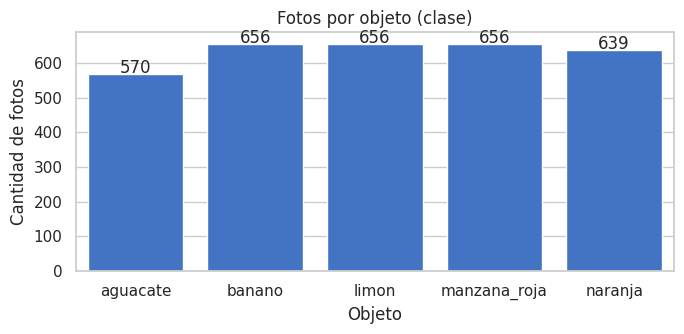

[INFO] 3177 imagenes en 5 clases
[INFO] Clase mas pequena: aguacate (570); mas grande: banano (656)


In [3]:
conteo = df["clase"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(7, 3.5))
sns.barplot(x=conteo.index, y=conteo.values, ax=ax, color="#2E6FD8")
for i, v in enumerate(conteo.values):
    ax.text(i, v + 1, str(v), ha="center")
ax.set(title="Fotos por objeto (clase)", xlabel="Objeto", ylabel="Cantidad de fotos")
plt.tight_layout(); plt.show()
print(f"[INFO] {len(df)} imagenes en {df['clase'].nunique()} clases")
print(f"[INFO] Clase mas pequena: {conteo.idxmin()} ({conteo.min()}); mas grande: {conteo.idxmax()} ({conteo.max()})")

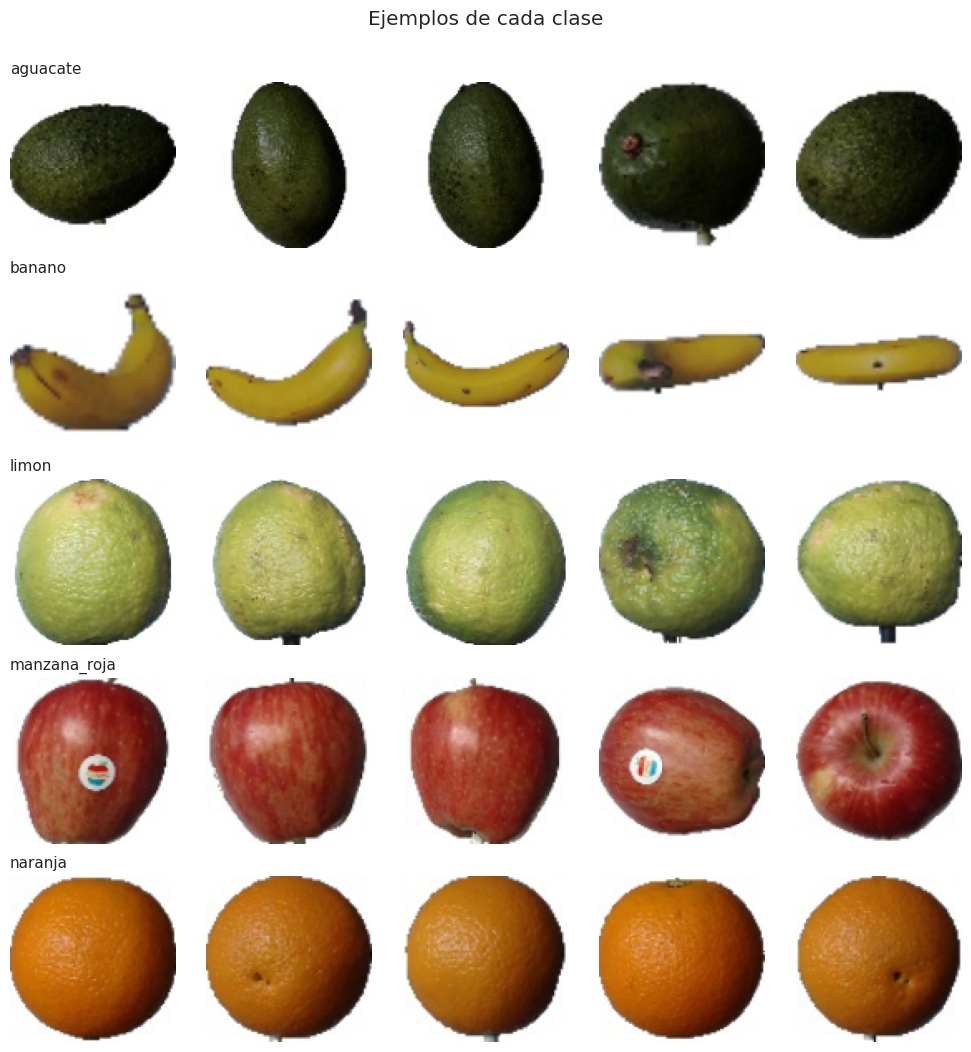

In [4]:
clases = sorted(df["clase"].unique())
fig, ejes = plt.subplots(len(clases), 5, figsize=(10, 2.1 * len(clases)))
ejes = np.atleast_2d(ejes)
for fila, clase in enumerate(clases):
    muestra = df[df["clase"] == clase].sample(min(5, (df["clase"] == clase).sum()), random_state=SEMILLA)
    for col in range(5):
        eje = ejes[fila, col]
        eje.axis("off")
        if col < len(muestra):
            eje.imshow(cargar_imagen(RAIZ / muestra.iloc[col]["ruta"]))
        if col == 0:
            eje.set_title(clase, loc="left", fontsize=11)
plt.suptitle("Ejemplos de cada clase", y=1.0)
plt.tight_layout(); plt.show()

## 3. Análisis exploratorio (EDA)

### 3.1 Extracción de características

El SVM no recibe píxeles sueltos sino un vector que resume cada foto (función `extraer_caracteristicas` de `src/preprocessing.py`):

| Bloque | Qué describe | Valores |
|---|---|---|
| Histograma H (tono) | Qué colores tiene el objeto | 16 |
| Histograma S (saturación) | Qué tan vivos son los colores | 8 |
| Histograma V (brillo) | Qué tan clara u oscura es la foto | 8 |
| HOG | Dirección de los bordes en cada zona: la forma del objeto | 1.764 |

Antes de calcularlo, cada foto se recorta al cuadrado central y se reduce a 128 × 128 píxeles.

In [5]:
inicio = time.time()
X_total = np.vstack([extraer_caracteristicas(cargar_imagen(RAIZ / r)) for r in df["ruta"]])
columnas = nombres_caracteristicas()
caracteristicas = pd.DataFrame(X_total, columns=columnas)
caracteristicas.insert(0, "clase", df["clase"].values)
caracteristicas.insert(0, "ruta", df["ruta"].values)
caracteristicas.to_csv(CARPETA_PROCESADA / "caracteristicas.csv", index=False)
print(f"[OK] Matriz de caracteristicas: {X_total.shape[0]} imagenes x {X_total.shape[1]} variables "
      f"({time.time() - inicio:.1f} s)")
print(f"[OK] Guardada en data/processed/caracteristicas.csv")

[OK] Matriz de caracteristicas: 3177 imagenes x 1796 variables (16.9 s)
[OK] Guardada en data/processed/caracteristicas.csv


### 3.2 Valores nulos y duplicados

In [6]:
nulos = int(caracteristicas[columnas].isna().sum().sum())
infinitos = int(np.isinf(X_total).sum())
duplicados = int(df["hash"].duplicated().sum())
print(f"[INFO] Valores nulos: {nulos} | infinitos: {infinitos} | fotos duplicadas exactas: {duplicados}")

[INFO] Valores nulos: 0 | infinitos: 0 | fotos duplicadas exactas: 0


### 3.3 Distribución de las variables de color

Si cada objeto tiene un color dominante distinto, sus histogramas de tono deben verse diferentes. Se grafica el histograma H promedio de cada clase.

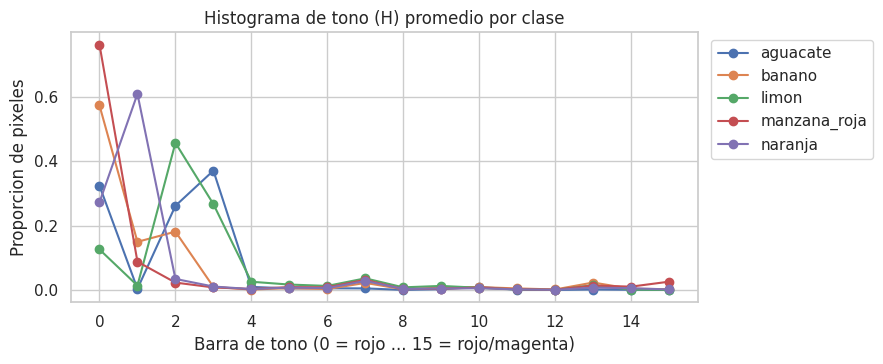

In [7]:
cols_h = [c for c in columnas if c.startswith("h_")]
promedio_h = caracteristicas.groupby("clase")[cols_h].mean()
fig, ax = plt.subplots(figsize=(9, 3.8))
for clase, fila in promedio_h.iterrows():
    ax.plot(range(len(cols_h)), fila.values, marker="o", label=clase)
ax.set(title="Histograma de tono (H) promedio por clase", xlabel="Barra de tono (0 = rojo ... 15 = rojo/magenta)",
       ylabel="Proporcion de pixeles")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout(); plt.show()

### 3.4 Correlaciones

Correlación entre las 32 variables de color. Bloques muy correlacionados indican información redundante; el SVM con estandarización lo tolera bien, pero es útil conocerlo.

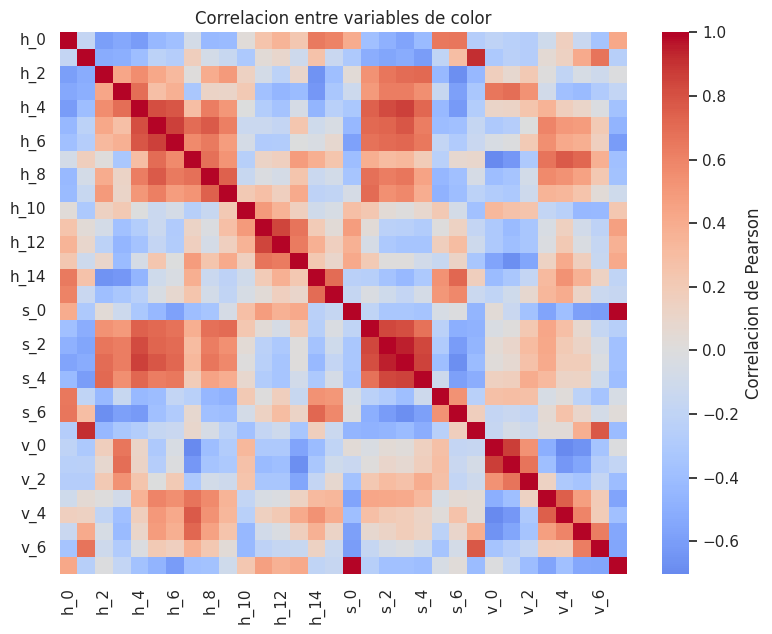

In [8]:
cols_color = [c for c in columnas if c[0] in "hsv" and not c.startswith("hog")]
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(caracteristicas[cols_color].corr(), cmap="coolwarm", center=0, ax=ax,
            cbar_kws={"label": "Correlacion de Pearson"})
ax.set_title("Correlacion entre variables de color")
plt.tight_layout(); plt.show()

### 3.5 Outliers

Se mide el brillo medio de cada foto. Fotos con brillo muy distinto al de su clase (|z| > 3) pueden estar sobreexpuestas, muy oscuras o tapadas; se revisan a ojo antes de decidir si se quitan.

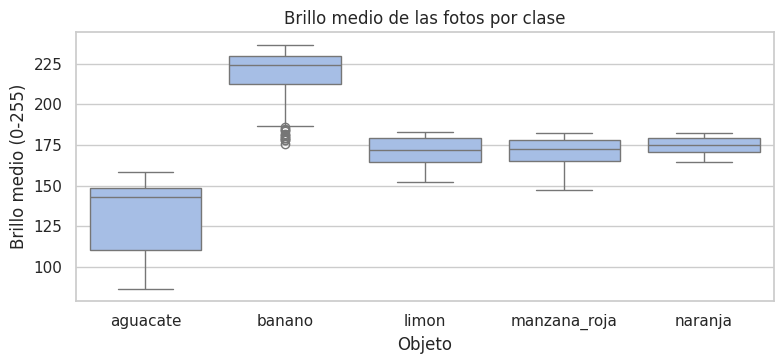

[INFO] Fotos con brillo atipico (|z| > 3): 10


,ruta,clase,brillo,z_brillo
749,data/raw/banano/banano_a_179.jpg,banano,181.964966,-3.063519
750,data/raw/banano/banano_a_180.jpg,banano,180.392517,-3.189987
751,data/raw/banano/banano_a_181.jpg,banano,179.185303,-3.287081
752,data/raw/banano/banano_a_182.jpg,banano,178.032166,-3.379826
753,data/raw/banano/banano_a_183.jpg,banano,175.565979,-3.578176
754,data/raw/banano/banano_a_184.jpg,banano,179.100464,-3.293905
755,data/raw/banano/banano_a_185.jpg,banano,177.951050,-3.386350
756,data/raw/banano/banano_a_186.jpg,banano,181.192200,-3.125671
2437,data/raw/manzana_roja/manzana_roja_b_227.jpg,manzana_roja,147.691711,-3.053640
2438,data/raw/manzana_roja/manzana_roja_b_228.jpg,manzana_roja,147.516846,-3.076412


In [9]:
brillo = []
for r in df["ruta"]:
    v = np.asarray(normalizar_imagen(cargar_imagen(RAIZ / r)).convert("HSV"))[:, :, 2]
    brillo.append(v.mean())
df["brillo"] = brillo
df["z_brillo"] = df.groupby("clase")["brillo"].transform(lambda s: (s - s.mean()) / (s.std(ddof=0) + 1e-9))
atipicas = df[df["z_brillo"].abs() > 3]

fig, ax = plt.subplots(figsize=(8, 3.8))
sns.boxplot(data=df, x="clase", y="brillo", ax=ax, color="#9BBCF0")
ax.set(title="Brillo medio de las fotos por clase", xlabel="Objeto", ylabel="Brillo medio (0-255)")
plt.tight_layout(); plt.show()
print(f"[INFO] Fotos con brillo atipico (|z| > 3): {len(atipicas)}")
atipicas[["ruta", "clase", "brillo", "z_brillo"]]

**Decisión sobre outliers:** las fotos atípicas por brillo se conservan si el objeto se ve, porque en la demostración la luz también puede variar; solo se eliminarían de `data/raw/` si la foto no muestra el objeto.

## 4. Preprocesamiento

1. **Limpieza:** se quitan fotos duplicadas exactas (mismo hash).
2. **Codificación:** la clase es texto y scikit-learn la acepta directamente en `SVC`; no hay otras variables categóricas.
3. **División train/test por bloques:** las fotos consecutivas de una ráfaga (o de un video) son casi idénticas. Si una queda en entrenamiento y su vecina en prueba, el modelo "se sabe" la prueba y la métrica sale inflada (*data leakage*). Por eso las fotos se agrupan en bloques de 30 consecutivas y cada bloque completo va a entrenamiento o a prueba: aproximadamente 80 % / 20 %, estratificado por clase y con semilla fija.
4. **Aumento de datos (solo entrenamiento):** a cada foto de entrenamiento se le agrega su versión espejo (volteo horizontal). Así el modelo ve el objeto desde más ángulos. La prueba no se aumenta para que la evaluación sea honesta.
5. **Estandarización:** `StandardScaler` dentro del pipeline; la media y la desviación se calculan solo con entrenamiento (sin *data leakage*).

In [10]:
mascara = ~df["hash"].duplicated()
df_limpio = df[mascara].reset_index(drop=True)
X_limpio = X_total[mascara.values]
y_limpio = df_limpio["clase"].values

TAM_BLOQUE = 30

def bloque(ruta):
    nombre, _, numero = Path(ruta).stem.rpartition("_")
    return f"{nombre}_{int(numero) // TAM_BLOQUE}" if numero.isdigit() else Path(ruta).stem

bloques = df_limpio["ruta"].map(bloque).values
division = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
idx_train, idx_test = next(division.split(np.zeros(len(y_limpio)), y_limpio, groups=bloques))
assert not set(bloques[idx_train]) & set(bloques[idx_test]), "Un bloque quedo en ambos conjuntos"
print(f"[INFO] {len(set(bloques))} bloques de fotos consecutivas; ninguno compartido entre entrenamiento y prueba")
X_train_orig, X_test = X_limpio[idx_train], X_limpio[idx_test]
y_train_orig, y_test = y_limpio[idx_train], y_limpio[idx_test]

X_espejo = np.vstack([
    extraer_caracteristicas(ImageOps.mirror(cargar_imagen(RAIZ / df_limpio.loc[i, "ruta"]))) for i in idx_train
])
X_train = np.vstack([X_train_orig, X_espejo])
y_train = np.concatenate([y_train_orig, y_train_orig])

print(f"[INFO] Entrenamiento: {len(idx_train)} fotos (+{len(X_espejo)} espejos = {len(X_train)} ejemplos)")
print(f"[INFO] Prueba: {len(idx_test)} fotos")
pd.DataFrame({"entrenamiento": pd.Series(y_train_orig).value_counts(),
              "prueba": pd.Series(y_test).value_counts()}).sort_index()

[INFO] 108 bloques de fotos consecutivas; ninguno compartido entre entrenamiento y prueba


[INFO] Entrenamiento: 2551 fotos (+2551 espejos = 5102 ejemplos)
[INFO] Prueba: 626 fotos


,entrenamiento,prueba
aguacate,452,118
banano,538,118
limon,536,120
manzana_roja,506,150
naranja,519,120


## 5. Entrenamiento del modelo

**Modelo:** `Pipeline(StandardScaler → SVC)`. El SVC usa `probability=True` para que la app pueda mostrar la confianza de cada predicción.

**Búsqueda de hiperparámetros** con validación cruzada estratificada de 3 particiones, optimizando F1 macro. Durante la búsqueda el SVC no calcula probabilidades (es más rápido); el modelo final se reentrena con los mejores hiperparámetros y `probability=True`:

- `kernel`: lineal o RBF (frontera curva).
- `C`: cuánto se castigan los errores; alto = frontera más ajustada, bajo = margen más amplio.
- `gamma` (solo RBF): qué tan local es la influencia de cada ejemplo.

Para que la validación cruzada sea justa, se usan los mismos bloques de fotos consecutivas: un bloque (y los espejos de sus fotos) queda siempre en una sola partición.

Como referencia se entrena también un `DummyClassifier`, que siempre predice la clase más frecuente: el SVM debe superarlo con amplitud.

In [11]:
grupos = np.concatenate([bloques[idx_train], bloques[idx_train]])
pipeline = Pipeline([
    ("escalador", StandardScaler()),
    ("svm", SVC(random_state=SEMILLA)),
])
rejilla = [
    {"svm__kernel": ["linear"], "svm__C": [0.01, 0.1]},
    {"svm__kernel": ["rbf"], "svm__C": [1, 10], "svm__gamma": ["scale", 1e-3]},
]
busqueda = GridSearchCV(pipeline, rejilla, scoring="f1_macro", n_jobs=1,
                        cv=StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEMILLA))
inicio = time.time()
busqueda.fit(X_train, y_train, groups=grupos)
print(f"[OK] {len(busqueda.cv_results_['params'])} configuraciones evaluadas en {time.time() - inicio:.1f} s")
print(f"[OK] Mejores hiperparametros: {busqueda.best_params_}")
print(f"[OK] F1 macro en validacion cruzada: {busqueda.best_score_:.3f}")

resultados = pd.DataFrame(busqueda.cv_results_)[["params", "mean_test_score", "std_test_score", "rank_test_score"]]
resultados.sort_values("rank_test_score").head(10)

[OK] 6 configuraciones evaluadas en 73.2 s
[OK] Mejores hiperparametros: {'svm__C': 0.01, 'svm__kernel': 'linear'}
[OK] F1 macro en validacion cruzada: 0.999


,params,mean_test_score,std_test_score,rank_test_score
0,"{'svm__C': 0.01, 'svm__kernel': 'linear'}",0.998889,0.001571,1
1,"{'svm__C': 0.1, 'svm__kernel': 'linear'}",0.998889,0.001571,1
4,"{'svm__C': 10, 'svm__gamma': 'scale', 'svm__ke...",0.989294,0.010013,3
2,"{'svm__C': 1, 'svm__gamma': 'scale', 'svm__ker...",0.989102,0.009966,4
3,"{'svm__C': 1, 'svm__gamma': 0.001, 'svm__kerne...",0.978593,0.011071,5
5,"{'svm__C': 10, 'svm__gamma': 0.001, 'svm__kern...",0.978593,0.011071,5


In [12]:
modelo = Pipeline([
    ("escalador", StandardScaler()),
    ("svm", SVC(probability=True, random_state=SEMILLA)),
]).set_params(**busqueda.best_params_)
modelo.fit(X_train, y_train)
print(f"[OK] Modelo final reentrenado con probabilidades: {busqueda.best_params_}")
base = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
print(f"[INFO] Accuracy del clasificador base (clase mas frecuente): {accuracy_score(y_test, base.predict(X_test)):.1%}")

[OK] Modelo final reentrenado con probabilidades: {'svm__C': 0.01, 'svm__kernel': 'linear'}
[INFO] Accuracy del clasificador base (clase mas frecuente): 18.8%


## 6. Evaluación

Se evalúa con las fotos de **prueba**, que el modelo nunca vio. Métricas:

- **Accuracy:** proporción de fotos bien clasificadas.
- **Precision:** de las veces que dijo "taza", cuántas eran taza.
- **Recall:** de las tazas reales, cuántas reconoció.
- **F1:** media armónica de precision y recall. Se reporta el promedio macro (todas las clases pesan igual).

In [13]:
y_pred = modelo.predict(X_test)
metricas = {
    "accuracy": accuracy_score(y_test, y_pred),
    "precision_macro": precision_score(y_test, y_pred, average="macro", zero_division=0),
    "recall_macro": recall_score(y_test, y_pred, average="macro", zero_division=0),
    "f1_macro": f1_score(y_test, y_pred, average="macro", zero_division=0),
}
for nombre, valor in metricas.items():
    print(f"[OK] {nombre}: {valor:.1%}")
print()
print(classification_report(y_test, y_pred, zero_division=0))

[OK] accuracy: 100.0%
[OK] precision_macro: 100.0%
[OK] recall_macro: 100.0%
[OK] f1_macro: 100.0%

              precision    recall  f1-score   support

    aguacate       1.00      1.00      1.00       118
      banano       1.00      1.00      1.00       118
       limon       1.00      1.00      1.00       120
manzana_roja       1.00      1.00      1.00       150
     naranja       1.00      1.00      1.00       120

    accuracy                           1.00       626
   macro avg       1.00      1.00      1.00       626
weighted avg       1.00      1.00      1.00       626



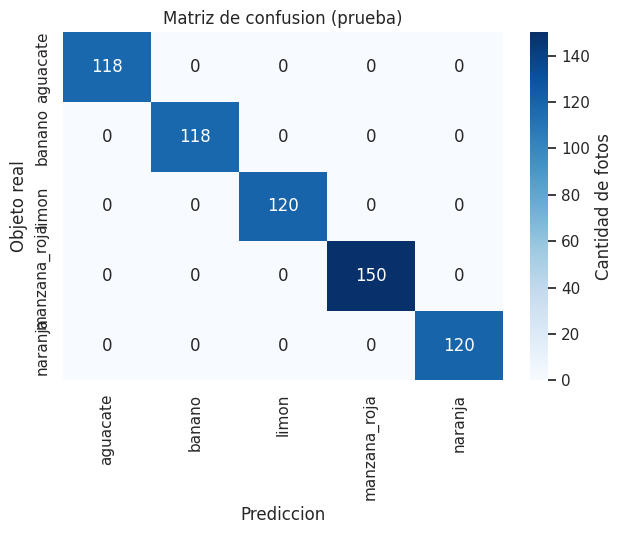

In [14]:
etiquetas = list(modelo.classes_)
matriz = confusion_matrix(y_test, y_pred, labels=etiquetas)
fig, ax = plt.subplots(figsize=(6.5, 5.5))
sns.heatmap(matriz, annot=True, fmt="d", cmap="Blues", xticklabels=etiquetas, yticklabels=etiquetas, ax=ax,
            cbar_kws={"label": "Cantidad de fotos"})
ax.set(title="Matriz de confusion (prueba)", xlabel="Prediccion", ylabel="Objeto real")
plt.tight_layout(); plt.show()

### 6.1 Confianza y errores

La app solo acepta una predicción si la probabilidad más alta supera un umbral. Se grafica la confianza de los aciertos y de los errores para elegir ese umbral, y se muestran las fotos mal clasificadas.

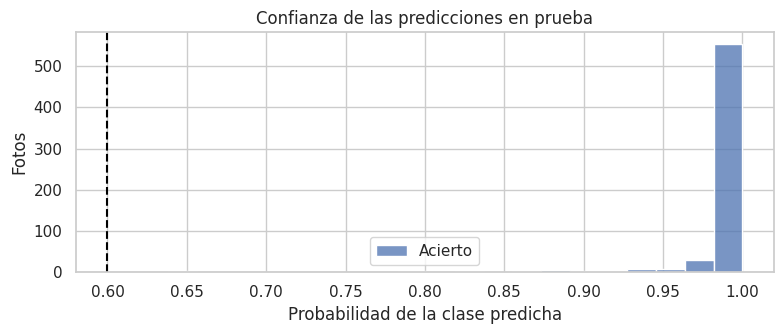

[INFO] Umbral 0.50: acepta 100% de las fotos, con 100.0% de acierto
[INFO] Umbral 0.60: acepta 100% de las fotos, con 100.0% de acierto
[INFO] Umbral 0.70: acepta 100% de las fotos, con 100.0% de acierto
[INFO] Umbral 0.80: acepta 98% de las fotos, con 100.0% de acierto
[INFO] Fotos mal clasificadas: 0 de 626


In [15]:
probas = modelo.predict_proba(X_test).max(axis=1)
acierto = y_pred == y_test
fig, ax = plt.subplots(figsize=(8, 3.5))
sns.histplot(x=probas, hue=np.where(acierto, "Acierto", "Error"), bins=20, ax=ax, multiple="stack")
ax.axvline(0.6, color="black", ls="--", label="Umbral por defecto de la app (0,60)")
ax.set(title="Confianza de las predicciones en prueba", xlabel="Probabilidad de la clase predicha", ylabel="Fotos")
plt.tight_layout(); plt.show()
for u in (0.5, 0.6, 0.7, 0.8):
    aceptadas = probas >= u
    exactitud = acierto[aceptadas].mean() if aceptadas.any() else float("nan")
    print(f"[INFO] Umbral {u:.2f}: acepta {aceptadas.mean():.0%} de las fotos, con {exactitud:.1%} de acierto")

errores = np.where(~acierto)[0]
print(f"[INFO] Fotos mal clasificadas: {len(errores)} de {len(y_test)}")
if len(errores):
    n = min(8, len(errores))
    fig, ejes = plt.subplots(1, n, figsize=(2.2 * n, 2.6))
    for eje, i in zip(np.atleast_1d(ejes), errores[:n]):
        eje.imshow(cargar_imagen(RAIZ / df_limpio.loc[idx_test[i], "ruta"]))
        eje.set_title(f"real: {y_test[i]}\npred: {y_pred[i]}", fontsize=8)
        eje.axis("off")
    plt.tight_layout(); plt.show()

## 7. Serialización del modelo

Se guarda el pipeline completo (escalador + SVM) en `models/modelo.pkl` con `joblib`, junto con `models/metadata.json` (clases, hiperparámetros, métricas y versiones). Luego se carga de nuevo y se verifica que predice lo mismo.

In [16]:
ruta_modelo = CARPETA_MODELOS / "modelo.pkl"
joblib.dump(modelo, ruta_modelo, compress=3)
metadatos = {
    "algoritmo": "Support Vector Machine (sklearn.svm.SVC)",
    "fecha_entrenamiento": datetime.now().isoformat(timespec="seconds"),
    "clases": etiquetas,
    "mejores_hiperparametros": {k.replace("svm__", ""): v for k, v in busqueda.best_params_.items()},
    "f1_macro_validacion_cruzada": round(float(busqueda.best_score_), 4),
    "metricas": {k: round(float(v), 4) for k, v in metricas.items()},
    "imagenes": {"total": int(len(df_limpio)), "entrenamiento": int(len(idx_train)), "prueba": int(len(idx_test))},
    "n_caracteristicas": int(X_total.shape[1]),
    "versiones": {"scikit-learn": sklearn.__version__, "numpy": np.__version__},
}
(CARPETA_MODELOS / "metadata.json").write_text(json.dumps(metadatos, indent=2, ensure_ascii=False), encoding="utf-8")

recargado = joblib.load(ruta_modelo)
iguales = bool((recargado.predict(X_test) == y_pred).all())
print(f"[OK] Modelo guardado en models/modelo.pkl ({ruta_modelo.stat().st_size / 1024:.0f} KB)")
print(f"[OK] El modelo recargado predice igual que el original: {iguales}")

[OK] Modelo guardado en models/modelo.pkl (6474 KB)
[OK] El modelo recargado predice igual que el original: True


## 8. Resumen para el avance

In [17]:
print("Estado del Modelo:")
print("- Modelo entrenado: SI")
print("- Archivo: models/modelo.pkl")
print(f"- Clases: {', '.join(etiquetas)}")
print(f"- Imagenes: {len(df_limpio)} ({len(idx_train)} entrenamiento / {len(idx_test)} prueba)")
print(f"- Mejores hiperparametros: {metadatos['mejores_hiperparametros']}")
print(f"- Accuracy: {metricas['accuracy']:.1%}")
print(f"- Precision (macro): {metricas['precision_macro']:.1%}")
print(f"- Recall (macro): {metricas['recall_macro']:.1%}")
print(f"- F1 (macro): {metricas['f1_macro']:.1%}")

Estado del Modelo:
- Modelo entrenado: SI
- Archivo: models/modelo.pkl
- Clases: aguacate, banano, limon, manzana_roja, naranja
- Imagenes: 3177 (2551 entrenamiento / 626 prueba)
- Mejores hiperparametros: {'C': 0.01, 'kernel': 'linear'}
- Accuracy: 100.0%
- Precision (macro): 100.0%
- Recall (macro): 100.0%
- F1 (macro): 100.0%


## 9. Conclusiones preliminares

- El modelo SVM se entrena desde cero con fotos propias, sin modelos pre-entrenados, y queda serializado para la aplicación.
- La matriz de confusión muestra qué objetos se confunden entre sí; esos son los que conviene fotografiar más (otras posiciones, otra luz).
- **Limitaciones:** el modelo solo conoce los objetos con los que se entrenó y depende de que el fondo y la luz se parezcan a los de las fotos de entrenamiento. Un objeto nuevo siempre se parecerá a alguno conocido; por eso la app usa un umbral de confianza.
- **Mejoras posibles:** más fotos por objeto y en más lugares, una clase "sin objeto", y características adicionales (por ejemplo, textura con LBP).